# IAD — PatchCore Clean Baseline

**Purpose:** Reproducible clean-data baseline for the M.Tech Industrial Visual Anomaly Detection research.

**Dataset:** MVTec AD — Bottle  
**Model:** ImageNet-pretrained WideResNet50 + PatchCore  
**Scope:** Clean training data only. Contamination experiments are separate.



**Step 1: Imports**




In [1]:
import os
import sys
import json
import time
import tarfile
import subprocess
import shutil
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from PIL import Image
from torch.utils.data import DataLoader

**Step 2: Experiment Configuration**

In [2]:
CATEGORY = "bottle"

# PatchCore configuration
BACKBONE = "wideresnet50"
LAYERS = ["layer2", "layer3"]

RESIZE = 256
IMAGE_SIZE = 224

PRETRAIN_EMBED_DIM = 1024
TARGET_EMBED_DIM = 1024

PATCH_SIZE = 3
NEAREST_NEIGHBOURS = 1

CORESET_PERCENTAGE = 0.10
SEED = 0

GPU_ID = 0
NUM_WORKERS = 2

# CPU FAISS because current Colab environment has faiss-cpu
FAISS_ON_GPU = False

print("Category:", CATEGORY)
print("Backbone:", BACKBONE)
print("Layers:", LAYERS)
print("Seed:", SEED)

Category: bottle
Backbone: wideresnet50
Layers: ['layer2', 'layer3']
Seed: 0


**Step 3: Mount Drive**

In [4]:
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

print("Google Drive mounted:",
      os.path.exists("/content/drive/MyDrive"))

Mounted at /content/drive
Google Drive mounted: True


**Step 4: Check GPU**

In [5]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(GPU_ID))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


**Step 5. Install the Official PatchCore Implementation**

Install the repository and editable package before importing PatchCore.

In [12]:
import os
import sys
import subprocess

REPO = "/content/patchcore-inspection"

if not os.path.exists(REPO):
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/amazon-science/patchcore-inspection.git",
            REPO
        ],
        check=True
    )

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q",
        "-r", os.path.join(REPO, "requirements.txt")
    ],
    check=True
)

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q", "-e", REPO
    ],
    check=True
)

os.chdir(REPO)

# Append the package source directory to sys.path so Python can find 'patchcore' immediately
src_path = os.path.join(REPO, "src")
if src_path not in sys.path:
    sys.path.append(src_path)

import patchcore

print("PatchCore import: SUCCESS")
print("Repository:", REPO)

PatchCore import: SUCCESS
Repository: /content/patchcore-inspection


**Step 6:. Check and Extract the Bottle Dataset**

Read the existing archive directly from Google Drive. No manual re-upload to Colab is required.

In [13]:
CATEGORY_PATH = os.path.join(
    REPO,
    CATEGORY
)

if os.path.exists(CATEGORY_PATH):
    print(f"{CATEGORY} already extracted.")
else:
    print(f"Extracting {CATEGORY}...")

    with tarfile.open(
        CATEGORY_ARCHIVE,
        "r:xz"
    ) as tar:
        tar.extractall(
            REPO,
            filter="data"
        )

    print("Extraction complete.")

print("Category path:")
print(CATEGORY_PATH)

Extracting bottle...
Extraction complete.
Category path:
/content/patchcore-inspection/bottle


**Step 7: Verify Dataset**

In [14]:
train_good = os.path.join(
    CATEGORY_PATH,
    "train",
    "good"
)

test_path = os.path.join(
    CATEGORY_PATH,
    "test"
)

print("Train/good:", os.path.exists(train_good))
print("Test:", os.path.exists(test_path))

if not os.path.exists(train_good):
    raise FileNotFoundError("Training data not found.")

if not os.path.exists(test_path):
    raise FileNotFoundError("Test data not found.")

Train/good: True
Test: True


**Step 8: Dataset summary**

In [15]:
print("=" * 50)
print(f"MVTec AD — {CATEGORY.upper()}")
print("=" * 50)

print("\nTraining images:")
print("good:", len(os.listdir(train_good)))

print("\nTest categories:")

for folder in sorted(os.listdir(test_path)):
    folder_path = os.path.join(test_path, folder)

    if os.path.isdir(folder_path):
        print(
            f"{folder:20s}: "
            f"{len(os.listdir(folder_path))} images"
        )

MVTec AD — BOTTLE

Training images:
good: 209

Test categories:
broken_large        : 20 images
broken_small        : 22 images
contamination       : 21 images
good                : 20 images


**Dataset Summary and Sample Images**

**Observation:** The Bottle category contains 209 normal training images and 83 test images across four categories.

**Step 9: Check image size**

In [16]:
sample_files = sorted(
    glob.glob(
        os.path.join(
            train_good,
            "*.png"
        )
    )
)

sample_image = Image.open(sample_files[0])

print("Sample image:", sample_files[0])
print("Original size:", sample_image.size)

Sample image: /content/patchcore-inspection/bottle/train/good/000.png
Original size: (900, 900)


**Step 10: FAISS verification**

In [17]:
import faiss

print("FAISS version:", faiss.__version__)
print(
    "FAISS GPU support:",
    hasattr(faiss, "GpuIndexFlatL2")
)

if hasattr(faiss, "GpuIndexFlatL2"):
    print("FAISS GPU available.")
else:
    print("Using CPU FAISS.")

FAISS version: 1.15.1
FAISS GPU support: False
Using CPU FAISS.


**Step 11: Create experiment directory**

In [18]:
CATEGORY_EXPERIMENT_DIR = os.path.join(
    EXPERIMENTS_DRIVE,
    "PatchCore",
    CATEGORY
)

os.makedirs(
    CATEGORY_EXPERIMENT_DIR,
    exist_ok=True
)

print("Experiment directory:")
print(CATEGORY_EXPERIMENT_DIR)

Experiment directory:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle


**Step 12: Run CLEAN PatchCore baseline**

In [20]:
%cd /content/patchcore-inspection

print("Starting clean PatchCore baseline...\n")

# Define the missing RUN_NAME variable
RUN_NAME = "clean_baseline"

command = [
    sys.executable,
    "bin/run_patchcore.py",

    "--gpu", str(GPU_ID),
    "--seed", str(SEED),
    "--save_patchcore_model",

    "--log_group", RUN_NAME,
    "--log_project", "PatchCore",

    CATEGORY_EXPERIMENT_DIR,

    "patch_core",
    "-b", BACKBONE,
    "-le", "layer2",
    "-le", "layer3",

    "--pretrain_embed_dimension", str(PRETRAIN_EMBED_DIM),
    "--target_embed_dimension", str(TARGET_EMBED_DIM),
    "--anomaly_scorer_num_nn", str(NEAREST_NEIGHBOURS),
    "--patchsize", str(PATCH_SIZE),

    "sampler",
    "-p", str(CORESET_PERCENTAGE),
    "approx_greedy_coreset",

    "dataset",
    "--resize", str(RESIZE),
    "--imagesize", str(IMAGE_SIZE),
    "-d", CATEGORY,
    "mvtec", REPO
]

start_time = time.perf_counter()

result = subprocess.run(
    command,
    cwd=REPO
)

runtime = time.perf_counter() - start_time

print("\nRuntime:", round(runtime, 2), "seconds")
print("Return code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError(
        f"PatchCore baseline failed with return code {result.returncode}."
    )

print("\nPatchCore baseline completed successfully.")

/content/patchcore-inspection
Starting clean PatchCore baseline...


Runtime: 90.57 seconds
Return code: 0

PatchCore baseline completed successfully.


**Step 15:Verify saved model**

In [21]:
import os
import glob

print("Checking baseline outputs...\n")

run_folders = sorted(
    glob.glob(os.path.join(CATEGORY_EXPERIMENT_DIR, "PatchCore", f"{RUN_NAME}_*"))
)

if not run_folders:
    print(f"No run folders found under {os.path.join(CATEGORY_EXPERIMENT_DIR, 'PatchCore', f'{RUN_NAME}_*')}")

for folder in run_folders:
    print("Run folder:", folder)

    results_file = os.path.join(folder, "results.csv")
    model_dir = os.path.join(folder, "models")

    print("  results.csv:", os.path.exists(results_file))
    print("  models folder:", os.path.exists(model_dir))

    if os.path.exists(model_dir):
        print("  model contents:", os.listdir(model_dir))

Checking baseline outputs...

Run folder: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline_0
  results.csv: True
  models folder: True
  model contents: ['mvtec_bottle']
Run folder: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline_1
  results.csv: True
  models folder: True
  model contents: ['mvtec_bottle']
Run folder: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline_2
  results.csv: True
  models folder: True
  model contents: ['mvtec_bottle']


**Step 16: Read metrics**

In [22]:
BASELINE_RUN = run_folders[0]

RESULTS_CSV = os.path.join(
    BASELINE_RUN,
    "results.csv"
)

baseline_metrics = pd.read_csv(
    RESULTS_CSV
)

display(baseline_metrics)

,Row Names,instance_auroc,full_pixel_auroc,anomaly_pixel_auroc
0,mvtec_bottle,1.0,0.984839,0.979561
1,Mean,1.0,0.984839,0.979561


**Step 17: Save experiment configuration**

In [24]:
experiment_config = {
    "experiment": "clean_baseline",
    "category": CATEGORY,
    "model": "PatchCore",
    "backbone": BACKBONE,
    "layers": LAYERS,
    "resize": RESIZE,
    "image_size": IMAGE_SIZE,
    "pretrain_embed_dimension": PRETRAIN_EMBED_DIM,
    "target_embed_dimension": TARGET_EMBED_DIM,
    "patch_size": PATCH_SIZE,
    "nearest_neighbours": NEAREST_NEIGHBOURS,
    "coreset_percentage": CORESET_PERCENTAGE,
    "seed": SEED,
    "gpu": (
        torch.cuda.get_device_name(GPU_ID)
        if torch.cuda.is_available()
        else "CPU"
    ),
    "faiss_gpu": FAISS_ON_GPU,
    "num_workers": NUM_WORKERS,
    "runtime_seconds": runtime,
}

with open(
    os.path.join(
        BASELINE_RUN,
        "experiment_config.json"
    ),
    "w"
) as f:
    json.dump(
        experiment_config,
        f,
        indent=4
    )

with open(
    os.path.join(
        BASELINE_RUN,
        "command.txt"
    ),
    "w"
) as f:
    f.write(
        " ".join(command)
    )

print("Experiment configuration saved.")

Experiment configuration saved.


**Step 18: Load saved PatchCore model**

In [25]:
import torch
import patchcore

**Step 19: Load clean baseline results**

In [26]:
import os
import pandas as pd

RESULTS_FILE = os.path.join(
    CATEGORY_EXPERIMENT_DIR,
    "PatchCore",
    "clean_baseline",
    "results.csv"
)

print("Looking for:")
print(RESULTS_FILE)

if os.path.exists(RESULTS_FILE):
    results_df = pd.read_csv(RESULTS_FILE)

    print("\nClean baseline results loaded successfully.")
    display(results_df)
else:
    print("\nERROR: results.csv not found.")

Looking for:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline/results.csv

Clean baseline results loaded successfully.


,Row Names,instance_auroc,full_pixel_auroc,anomaly_pixel_auroc
0,mvtec_bottle,1.0,0.984839,0.979561
1,Mean,1.0,0.984839,0.979561


**Step 20: Save clean Baseline metrics**

In [27]:
baseline_metrics = {
    "Instance AUROC": results_df.loc[0, "instance_auroc"],
    "Full Pixel AUROC": results_df.loc[0, "full_pixel_auroc"],
    "Anomaly Pixel AUROC": results_df.loc[0, "anomaly_pixel_auroc"]
}

print("CLEAN PATCHCORE BASELINE")
print("-" * 35)

for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.6f}")

CLEAN PATCHCORE BASELINE
-----------------------------------
Instance AUROC: 1.000000
Full Pixel AUROC: 0.984839
Anomaly Pixel AUROC: 0.979561


**Step 21: Check bottle test images**

locate bottle dataset on google drive

In [28]:
import os
import glob

PROJECT_ROOT = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT"
)

ARCHIVE = os.path.join(
    PROJECT_ROOT,
    "Dataset",
    "bottle.tar.xz"
)

print("Dataset archive:")
print(ARCHIVE)
print("\nArchive exists:", os.path.exists(ARCHIVE))

Dataset archive:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Dataset/bottle.tar.xz

Archive exists: True


**Extract Bottle dataset for visualization**

In [29]:
VIS_DATASET_DIR = "/content/mvtec_bottle"

if not os.path.exists(VIS_DATASET_DIR):
    os.makedirs(VIS_DATASET_DIR, exist_ok=True)

    with tarfile.open(ARCHIVE, "r:xz") as tar:
        tar.extractall(VIS_DATASET_DIR)

    print("Bottle dataset extracted.")
else:
    print("Bottle dataset already extracted.")

print("\nChecking extracted contents:")
print(os.listdir(VIS_DATASET_DIR))

/tmp/ipykernel_588/613492970.py:7: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(VIS_DATASET_DIR)


Bottle dataset extracted.

Checking extracted contents:
['bottle']


**Verify bottle test data**

In [30]:
import os
import glob

BOTTLE_TEST_DIR = os.path.join(
    VIS_DATASET_DIR,
    "bottle",
    "test"
)

print("Bottle test directory:")
print(BOTTLE_TEST_DIR)

print("\nTest categories:")

for category in sorted(os.listdir(BOTTLE_TEST_DIR)):
    category_path = os.path.join(
        BOTTLE_TEST_DIR,
        category
    )

    if os.path.isdir(category_path):
        images = glob.glob(
            os.path.join(category_path, "*")
        )

        print(f"{category}: {len(images)} images")

Bottle test directory:
/content/mvtec_bottle/bottle/test

Test categories:
broken_large: 20 images
broken_small: 22 images
contamination: 21 images
good: 20 images



**Step 22: Display sample test images**

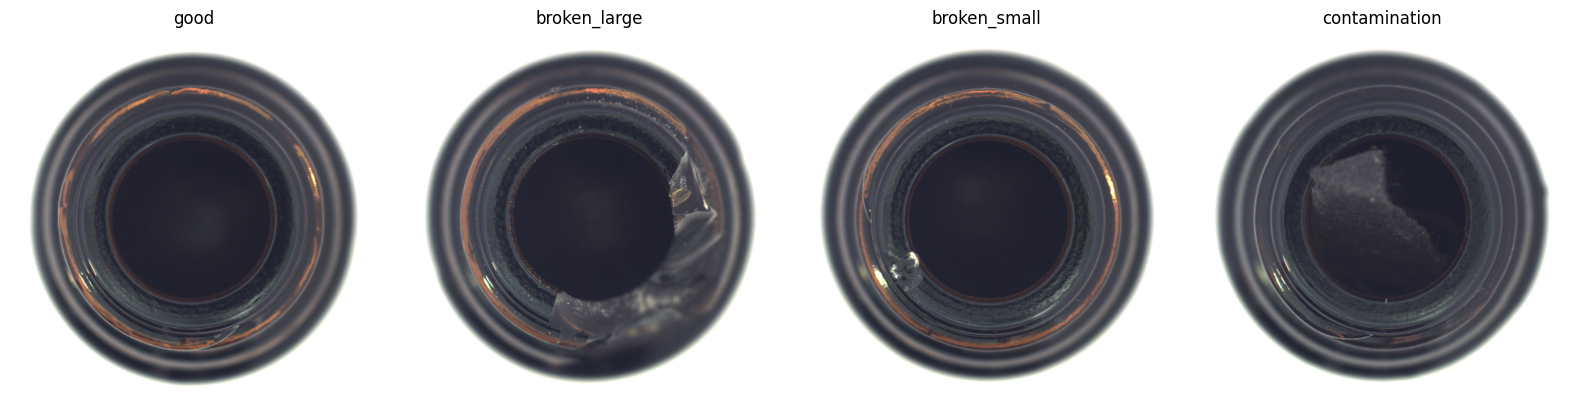

In [31]:
import matplotlib.pyplot as plt
from PIL import Image
import glob
import os

sample_categories = [
    "good",
    "broken_large",
    "broken_small",
    "contamination"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, category in zip(axes, sample_categories):

    image_path = sorted(
        glob.glob(
            os.path.join(
                BOTTLE_TEST_DIR,
                category,
                "*"
            )
        )
    )[0]

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Step 23: Check saved model and environment**

In [32]:
import os
import sys
import subprocess

MODEL_DIR = os.path.join(
    CATEGORY_EXPERIMENT_DIR,
    "models",
    "mvtec_bottle"
)

print("Saved model directory:")
print(MODEL_DIR)

print("\nModel files:")
if os.path.exists(MODEL_DIR):
    for root, dirs, files in os.walk(MODEL_DIR):
        for file in files:
            print(" -", os.path.join(root, file))
else:
    print("MODEL DIRECTORY NOT FOUND")

print("\nPython:")
print(sys.version)

print("\nPyTorch:")
print(subprocess.check_output(
    [sys.executable, "-c", "import torch; print(torch.__version__)"]
).decode().strip())

print("\ntimm:")
print(subprocess.check_output(
    [sys.executable, "-c", "import importlib.metadata as m; print(m.version('timm'))"]
).decode().strip())

Saved model directory:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/models/mvtec_bottle

Model files:
MODEL DIRECTORY NOT FOUND

Python:
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

PyTorch:
2.11.0+cu130

timm:
1.0.30


Locate the actual saved model

In [33]:
import os

PATCHCORE_ROOT = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "M.Tech AIML/Semester 1/Machine Learning/"
    "IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore"
)

print("Searching for saved model...\n")

for root, dirs, files in os.walk(PATCHCORE_ROOT):
    if "patchcore_params.pkl" in files:
        print("FOUND MODEL:")
        print(root)
        print("\nFiles:")
        for f in files:
            print(" -", f)

Searching for saved model...

FOUND MODEL:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle

Files:
 - nnscorer_search_index.faiss
 - patchcore_params.pkl
FOUND MODEL:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline_0/models/mvtec_bottle

Files:
 - nnscorer_search_index.faiss
 - patchcore_params.pkl
FOUND MODEL:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline_1/models/mvtec_bottle

Files:
 - nnscorer_search_index.faiss
 - patchcore_params.pkl
FOUND MODEL:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline_2/models/mvtec_bottle

Files:
 - nnscorer_search_index.faiss
 - patchcore_params.pkl


**Step 24: INSTALL PATCHCORE-COMPATIBLE TIMM**

In [34]:
%pip install -q --force-reinstall --no-deps timm==0.4.12

print("timm 0.4.12 installation completed.")

timm 0.4.12 installation completed.


**Test PatchCore import**

In [35]:
import subprocess
import sys

test_code = """
import torch
print("PyTorch:", torch.__version__)

import timm
print("timm:", timm.__version__)

from patchcore.patchcore import PatchCore
print("PatchCore import: SUCCESS")
"""

result = subprocess.run(
    [sys.executable, "-c", test_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("ERROR:")
    print(result.stderr)

print("Return code:", result.returncode)

PyTorch: 2.11.0+cu130
timm: 0.4.12
PatchCore import: SUCCESS

Return code: 0


**Step 25: TEST SAVED MODEL LOADING IN FRESH PROCESS**

In [36]:
import subprocess
import sys

MODEL_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "M.Tech AIML/Semester 1/Machine Learning/"
    "IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/"
    "clean_baseline/models/mvtec_bottle"
)

test_code = f"""
import torch
import timm

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)

from patchcore.patchcore import PatchCore
from patchcore.common import FaissNN

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

model = PatchCore(device)

model.load_from_path(
    load_path=r"{MODEL_DIR}",
    device=device,
    nn_method=FaissNN(False, 1)
)

print("MODEL_LOAD_SUCCESS")
"""

result = subprocess.run(
    [sys.executable, "-c", test_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("ERROR:")
    print(result.stderr)

print("Return code:", result.returncode)

PyTorch: 2.11.0+cu130
timm: 0.4.12
MODEL_LOAD_SUCCESS

ERROR:
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)

Return code: 0


In [37]:
import sys
import torch

# Patch for AttributeError: module 'torch' has no attribute '_utils'
# when loading models saved with older PyTorch versions. This provides
# a fallback for _element_size that was moved/removed in PyTorch 2.x.
if not hasattr(torch, '_utils'):
    class _DummyUtils:
        pass
    torch._utils = _DummyUtils()

if not hasattr(torch._utils, '_element_size'):
    try:
        torch._utils._element_size = torch.storage.element_size
    except AttributeError:
        # Fallback for very old PyTorch versions if torch.storage.element_size is also missing
        def _element_size_fallback(dtype):
            if dtype == torch.float32: return 4
            elif dtype == torch.float64: return 8
            elif dtype == torch.complex64: return 8
            elif dtype == torch.complex128: return 16
            elif dtype == torch.int64: return 8
            elif dtype == torch.int32: return 4
            elif dtype == torch.int16: return 2
            elif dtype == torch.int8: return 1
            elif dtype == torch.bool: return 1
            elif dtype == torch.uint8: return 1
            elif dtype == torch.bfloat16: return 2
            elif dtype == torch.float16: return 2
            raise ValueError(f"Unsupported dtype for _element_size: {dtype}")
        torch._utils._element_size = _element_size_fallback

# Remove 'timm' and 'patchcore' related modules from sys.modules to force a reload
# This is necessary because new 'pip install' might not automatically update
# modules already loaded in the current kernel session.
for module_name in list(sys.modules.keys()):
    if 'timm' in module_name or 'patchcore' in module_name:
        del sys.modules[module_name]

from patchcore.patchcore import PatchCore
from patchcore.common import FaissNN

MODEL_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "M.Tech AIML/Semester 1/Machine Learning/"
    "IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/"
    "clean_baseline/models/mvtec_bottle"
)

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Loading saved model...")

loaded_model = PatchCore(device)

loaded_model.load_from_path(
    load_path=MODEL_DIR,
    device=device,
    nn_method=FaissNN(
        False,   # CPU FAISS — important
        1
    )
)

print("\nSaved PatchCore model loaded successfully.")

Device: cuda:0
Loading saved model...


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Saved PatchCore model loaded successfully.


**Step 26: GENERATE PATCHCORE ANOMALY MAPS**

In [38]:
import os
import glob
import subprocess
import sys
import textwrap

MODEL_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "M.Tech AIML/Semester 1/Machine Learning/"
    "IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/"
    "clean_baseline/models/mvtec_bottle"
)

IMAGE_DIR = BOTTLE_TEST_DIR

# Pick one image from each class
selected_images = []

for category in ["good", "broken_large", "broken_small"]:
    image_path = sorted(
        glob.glob(os.path.join(IMAGE_DIR, category, "*"))
    )[0]
    selected_images.append((category, image_path))

print("Selected images:")
for category, path in selected_images:
    print(category, "->", path)

print("\nModel:")
print(MODEL_DIR)

Selected images:
good -> /content/mvtec_bottle/bottle/test/good/000.png
broken_large -> /content/mvtec_bottle/bottle/test/broken_large/000.png
broken_small -> /content/mvtec_bottle/bottle/test/broken_small/000.png

Model:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle


**Step 27: Run PatchCore prediction + Anomaly Maps**

In [39]:
import subprocess
import sys

OUTPUT_DIR = "/content/patchcore_visualization"

script = r'''
import os
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from patchcore.patchcore import PatchCore
from patchcore.common import FaissNN
from patchcore.datasets.mvtec import MVTecDataset, DatasetSplit

MODEL_DIR = r"''' + MODEL_DIR + r'''"
DATASET_ROOT = r"''' + IMAGE_DIR.rsplit("/bottle/test", 1)[0] + r'''"
OUTPUT_DIR = r"''' + OUTPUT_DIR + r'''"

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

model = PatchCore(device)

model.load_from_path(
    load_path=MODEL_DIR,
    device=device,
    nn_method=FaissNN(False, 1)
)

print("Model loaded.")

dataset = MVTecDataset(
    source=DATASET_ROOT,
    classname="bottle",
    resize=256,
    imagesize=224,
    split=DatasetSplit.TEST,
    seed=0,
    augment=False
)

print("Dataset loaded:", len(dataset))

dataloader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Running PatchCore prediction...")

prediction_output = model.predict(dataloader)

scores = prediction_output[0]
masks = prediction_output[1]

print("Prediction completed.")
print("Scores:", len(scores))
print("Masks:", len(masks))

# Create output folder
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save visualizations
for i in range(3):

    sample = dataset[i]

    image = sample["image"].numpy()
    image = image.transpose(1, 2, 0)

    image = image - image.min()
    image = image / (image.max() + 1e-8)

    mask = masks[i]

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Input")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap="jet")
    plt.title("PatchCore Anomaly Map")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(image)
    plt.imshow(mask, cmap="jet", alpha=0.5)
    plt.title("Overlay")
    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR + "/sample_" + str(i) + ".png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.close()

print("Visualizations saved successfully.")
print(OUTPUT_DIR)
'''

result = subprocess.run(
    [sys.executable, "-c", script],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("\nWARNINGS:")
    print(result.stderr)

print("\nReturn code:", result.returncode)

Model loaded.
Dataset loaded: 83
Running PatchCore prediction...
Prediction completed.
Scores: 83
Masks: 83
Visualizations saved successfully.
/content/patchcore_visualization


WARNINGS:
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)

Inferring...: 100%|██████████| 83/83 [00:33<00:00,  2.81it/s]
                                                             


Return code: 0


**Step 28: VIEW PATCHCORE ANOMALY MAPS**

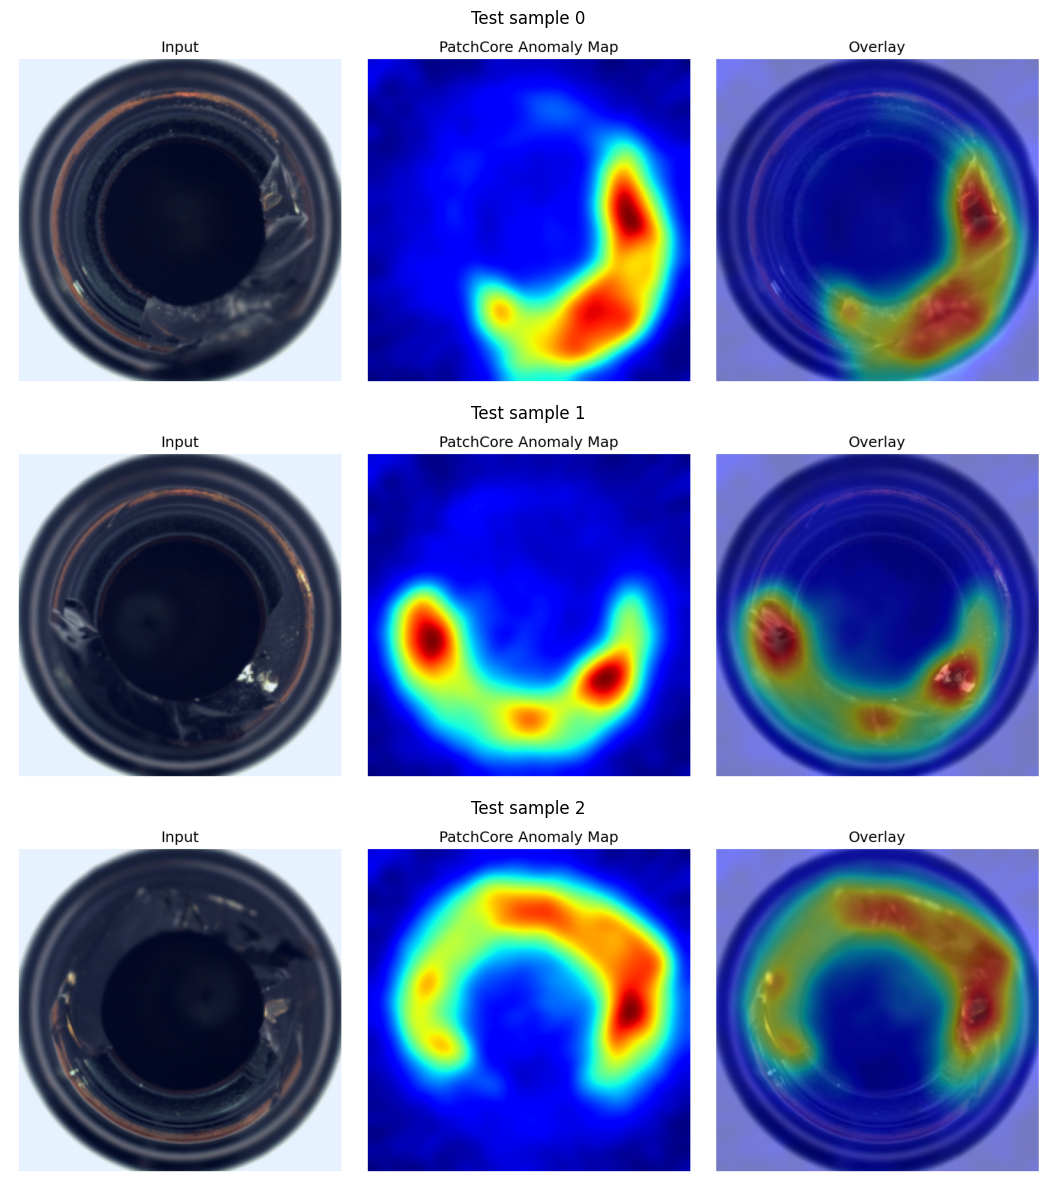

In [40]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

for i in range(3):
    image = Image.open(
        f"/content/patchcore_visualization/sample_{i}.png"
    )

    axes[i].imshow(image)
    axes[i].axis("off")
    axes[i].set_title(
        ["Test sample 0", "Test sample 1", "Test sample 2"][i]
    )

plt.tight_layout()
plt.show()

CHECK PATCHCORE MODULE

In [41]:
import subprocess

script = r"""
import patchcore.patchcore as pc

print("Module:", pc)
print("\nAvailable names:")
print([x for x in dir(pc) if not x.startswith("_")])
"""

result = subprocess.run(
    ["python", "-c", script],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("WARNINGS/ERRORS:")
    print(result.stderr)

print("Return code:", result.returncode)

Module: <module 'patchcore.patchcore' from '/content/patchcore-inspection/src/patchcore/patchcore.py'>

Available names:
['F', 'LOGGER', 'PatchCore', 'PatchMaker', 'logging', 'np', 'os', 'patchcore', 'pickle', 'torch', 'tqdm']

Return code: 0


CHECK PATCHCORE LOAD METHOD

In [42]:
import subprocess

script = r"""
import inspect
from patchcore.patchcore import PatchCore

print("load_from_path signature:")
print(inspect.signature(PatchCore.load_from_path))

print("\nPatchCore constructor signature:")
print(inspect.signature(PatchCore.__init__))
"""

result = subprocess.run(
    ["python", "-c", script],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("WARNINGS/ERRORS:")
    print(result.stderr)

print("Return code:", result.returncode)

load_from_path signature:
(self, load_path: str, device: torch.device, nn_method: <patchcore.common.FaissNN object at 0x7f50240befd0>, prepend: str = '') -> None

PatchCore constructor signature:
(self, device)

Return code: 0


CHECK FAISS NN SIGNATURE

In [43]:
import subprocess

script = r"""
import inspect
from patchcore.common import FaissNN

print("FaissNN constructor:")
print(inspect.signature(FaissNN.__init__))

print("\nFaissNN methods:")
print([x for x in dir(FaissNN) if not x.startswith("_")])
"""

result = subprocess.run(
    ["python", "-c", script],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("WARNINGS/ERRORS:")
    print(result.stderr)

print("Return code:", result.returncode)

FaissNN constructor:
(self, on_gpu: bool = False, num_workers: int = 4) -> None

FaissNN methods:
['fit', 'load', 'reset_index', 'run', 'save']

Return code: 0


**Step 29: CLASS-SPECIFIC PATCHCORE ANOMALY MAPS**

In [44]:
import os
import subprocess

script = r"""
import os
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import torch
import cv2

from patchcore.datasets.mvtec import MVTecDataset
from patchcore.datasets.mvtec import DatasetSplit
from patchcore.patchcore import PatchCore
from patchcore.common import FaissNN


# ============================================================
# PATHS
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle"

DATASET_PATH = "/content/mvtec_bottle"

OUT_DIR = "/content/patchcore_class_specific"
os.makedirs(OUT_DIR, exist_ok=True)


# ============================================================
# LOAD SAVED PATCHCORE MODEL
# ============================================================

device = torch.device("cuda")

model = PatchCore(device)

nn_method = FaissNN(
    on_gpu=False,
    num_workers=4
)

model.load_from_path(
    load_path=MODEL_PATH,
    device=device,
    nn_method=nn_method
)

print("Model loaded successfully.")


# ============================================================
# LOAD MVTec BOTTLE TEST DATASET
# ============================================================

dataset = MVTecDataset(
    source=DATASET_PATH,
    classname="bottle",
    resize=256,
    imagesize=224,
    split=DatasetSplit.TEST,
)

dataloader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Dataset loaded:", len(dataset))


# ============================================================
# FIND REQUIRED CATEGORIES
# ============================================================

wanted = {
    "good": None,
    "broken_large": None,
    "broken_small": None
}

for i, item in enumerate(dataset):

    path = item["image_path"]

    for category in wanted:

        if f"/{category}/" in path:

            if wanted[category] is None:
                wanted[category] = i

print("Selected indices:")
print(wanted)


# ============================================================
# RUN PATCHCORE
# ============================================================

print("Running PatchCore prediction...")

scores, masks, _, _ = model.predict(dataloader)

print("Prediction completed.")


# ============================================================
# CREATE VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)

categories = [
    "good",
    "broken_large",
    "broken_small"
]


for row, category in enumerate(categories):

    idx = wanted[category]

    item = dataset[idx]

    image_path = item["image_path"]

    # Load original image
    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Get anomaly map
    anomaly_map = masks[idx]

    anomaly_map = anomaly_map.astype(
        np.float32
    )

    anomaly_map -= anomaly_map.min()

    if anomaly_map.max() > 0:

        anomaly_map /= anomaly_map.max()


    # Input
    axes[row, 0].imshow(image)

    axes[row, 0].set_title(
        f"{category} - Input"
    )

    axes[row, 0].axis("off")


    # Anomaly map
    axes[row, 1].imshow(
        anomaly_map,
        cmap="jet"
    )

    axes[row, 1].set_title(
        "PatchCore Anomaly Map"
    )

    axes[row, 1].axis("off")


    # Overlay
    axes[row, 2].imshow(image)

    axes[row, 2].imshow(
        anomaly_map,
        cmap="jet",
        alpha=0.45
    )

    axes[row, 2].set_title(
        "Overlay"
    )

    axes[row, 2].axis("off")


# ============================================================
# SAVE
# ============================================================

plt.tight_layout()

output_path = os.path.join(
    OUT_DIR,
    "PatchCore_class_specific_visualization.png"
)

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_path)
"""



result = subprocess.run(
    ["python", "-c", script],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("WARNINGS/ERRORS:")
    print(result.stderr[-3000:])

print("Return code:", result.returncode)

Model loaded successfully.
Dataset loaded: 83
Selected indices:
{'good': 63, 'broken_large': 0, 'broken_small': 20}
Running PatchCore prediction...
Prediction completed.
Figure(1200x1200)
Saved:
/content/patchcore_class_specific/PatchCore_class_specific_visualization.png

WARNINGS/ERRORS:
00:12<00:16,  2.89it/s]
Inferring...: 100%|██████████| 83/83 [00:29<00:00,  2.82it/s]
                                                             

Return code: 0


**Step 30: Display the saved figure**

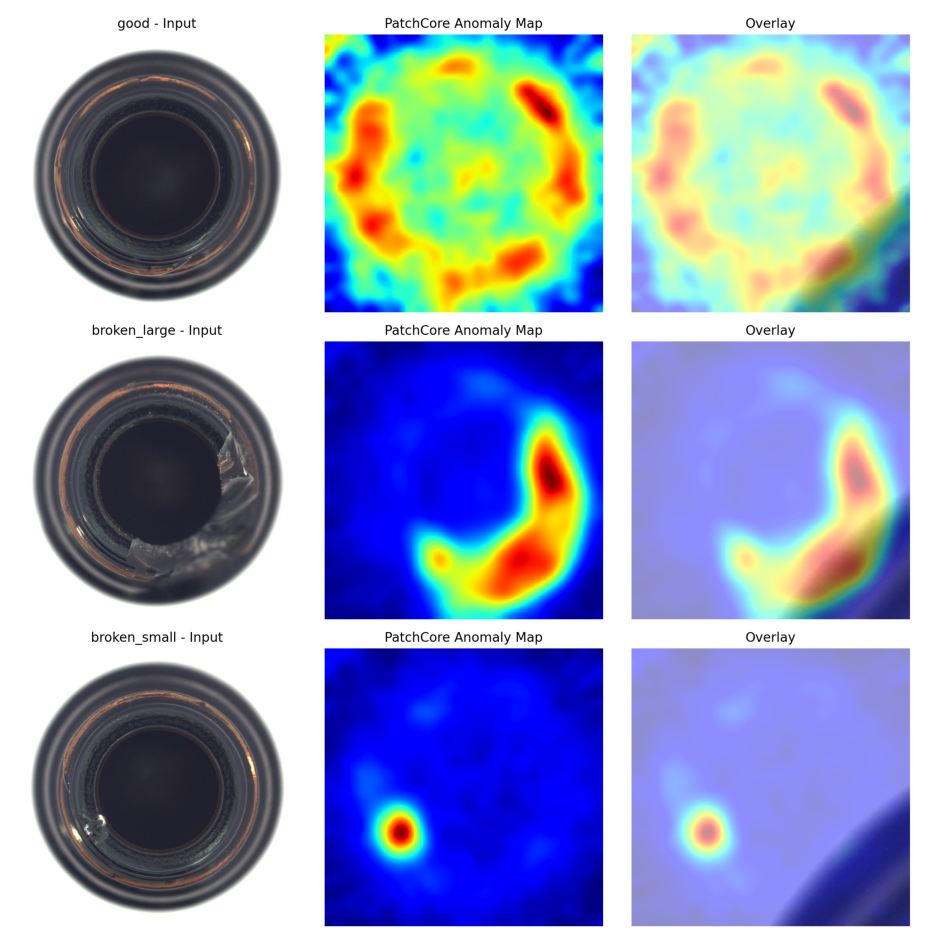

In [45]:
from PIL import Image
import matplotlib.pyplot as plt

path = "/content/patchcore_class_specific/PatchCore_class_specific_visualization.png"

img = Image.open(path)

plt.figure(figsize=(12, 12))
plt.imshow(img)
plt.axis("off")
plt.show()

### **Clean Baseline Conclusion**

PatchCore was successfully evaluated on the clean MVTec AD Bottle dataset using the fixed baseline configuration. The model achieved an Instance AUROC of 1.0000, Full Pixel AUROC of 0.9848, and Anomaly Pixel AUROC of 0.9796.

The anomaly-map visualization shows that PatchCore can localize visible defects in broken bottles. Some anomaly responses are also observed in defect-free regions of the good sample, indicating that visually unusual normal regions can receive elevated anomaly scores.

These results are recorded as the reference clean baseline for the subsequent experiments.

### Next Step: Training-Set Contamination

The next experiment will introduce controlled contamination into the normal training set while keeping the test set unchanged. Contamination levels will be evaluated systematically (e.g., 5%, 10%, and 20%) using the same PatchCore configuration and evaluation metrics.

The objective is to measure how contamination of the training normality model affects anomaly detection and localization performance.